# Jour 1 — Exploration du dataset Intel Image Classification

**Objectif du jour :** comprendre les données avant de construire un modèle, puis les séparer en **train / validation / test**.

## Étape 1 — Importer les outils et la configuration

**Problème :** on a besoin de bibliothèques pour manipuler les fichiers, les tableaux, les images et les graphiques.

In [3]:
import os 
import shutil
import random 
from pathlib import Path
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image  

from config import * 

sns.set_theme()
print("Classes : ",CLASSES)

Classes :  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## Étape 2 — Lister les images et compter par classe

**Problème :** combien d'images avons-nous ? Sont-elles réparties équitablement entre les 6 classes ?
Si une classe est beaucoup plus petite que les autres, le modèle risque de la négliger (**déséquilibre des classes**).

**Explication du code :**
- La fonction `lister_images` parcourt chaque dossier de classe et crée **une ligne par image** (chemin + classe).
- `value_counts()` compte le nombre d'images par classe.

classe
buildings    2628
forest       2745
glacier      2957
mountain     3037
sea          2784
street       2883
Name: count, dtype: int64

 Total :  17034 images


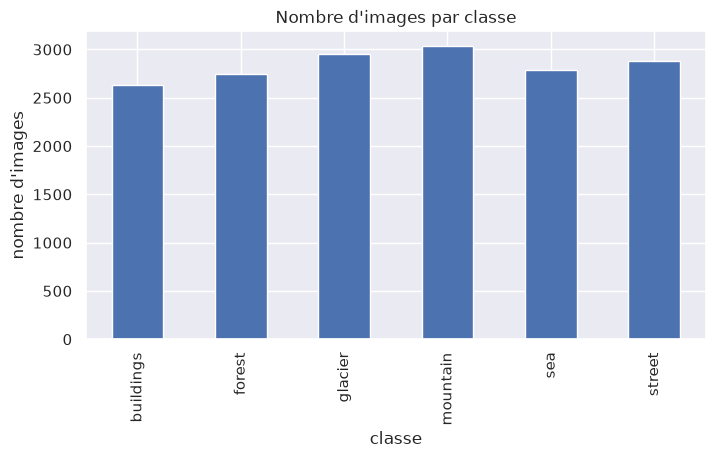

In [6]:
assert RAW_TRAIN_DIR.exists(), f"Dossier introuvable : {RAW_TRAIN_DIR} -> verifiez config.py"

def lister_images(dossier):
    lignes = []
    for classe in CLASSES:
        for nom_fichier in sorted(os.listdir(dossier / classe)):
            lignes.append({"chemin": str(dossier / classe / nom_fichier), "classe": classe})
    return pd.DataFrame(lignes)

df = lister_images(RAW_TRAIN_DIR)

comptage = df["classe"].value_counts().loc[CLASSES]
print(comptage)
print("\n Total : ",len(df), "images")

comptage.plot(kind="bar", figsize=(8, 4), title="Nombre d'images par classe")
plt.ylabel("nombre d'images")
plt.show()


## Étape 3 — Visualiser quelques exemples

**Problème :** il faut *voir* les images pour comprendre ce que le modèle devra reconnaître
(et repérer d'éventuelles ressemblances entre classes, par exemple `glacier` et `mountain`).

**Explication du code :**
- On crée une grille avec 1 ligne par classe et 4 colonnes.
- `.sample(4)` choisit 4 images au hasard dans chaque classe.
- `imshow` affiche l'image, `axis("off")` cache les axes.